# Supplementary Figures S11 and S12: traditional bibliometric networks and the entropy of network centrality

Supplementary Fig. S11A (the normalized collaboration network in 2017) was drawn in Gephi from the edge list exported here. Supplementary Fig. S11B (the normalized citation network in 2017) was drawn in Gephi from the edge list exported here, computed from the country citation network of the 2017 publications (citation_network_2017.csv.gz, made by data_prep/make_data_FigS13_S18.py). Supplementary Fig. S13 is drawn in notebook 22.

It reads its input from the data folder (`path2data`). The figures are saved in the `figures` folder.

In [1]:
import os
import json
import gzip
import itertools
from itertools import chain
from collections import defaultdict
import pandas as pd
import numpy as np
import networkx as nx

import scipy.sparse as spsparse
import scipy.stats as spstats

from statsmodels.stats.multitest import multipletests as holm
import statsmodels.api as sm

import matplotlib.pylab as plt
import matplotlib.gridspec as gridspec
import matplotlib.transforms as mtransforms
import seaborn as sns

from sklearn.preprocessing import normalize

import pyscisci.all as pyscisci

# set this path to where the processed data (Source Data) is stored:
path2sourcedata = "Source Data"
# when the notebook is run from the code folder, the Source Data folder is one level up
if not os.path.exists(path2sourcedata):
    path2sourcedata = os.path.join("..", "Source Data")

# the processed input data are in the data folder, next to the Source Data folder
path2data = os.path.join(os.path.dirname(os.path.abspath(path2sourcedata)), 'data')

# the regenerated figures are saved in the figures folder
path2figures = os.path.join(os.path.dirname(os.path.abspath(path2sourcedata)), 'figures')
os.makedirs(path2figures, exist_ok=True)
os.makedirs(os.path.join(path2figures, 'networks'), exist_ok=True)

Please install python-Levenshtein to take full advantage of the NLP tools. 
 pip install python-Levenshtein
Please install sparse_dot_topn to take full advantage of the NLP tools. 
 pip install sparse_dot_topn


/Users/psp2nq/anaconda3/lib/python3.11/site-packages/dask/dataframe/__init__.py:49: FutureWarning: 
Dask dataframe query planning is disabled because dask-expr is not installed.

You can install it with `pip install dask[dataframe]` or `conda install dask`.
This will raise in a future version.

  warnings.warn(msg, FutureWarning)


## The citation preference network

In [2]:
country_auc_df = pd.read_csv(os.path.join(path2data, 'oa_countrycites_nosameorg_auc.csv.gz'))

country_auc_df['Zscore'] = (country_auc_df['AUC'] - 0.5)/np.sqrt(country_auc_df['Cov'])

    
country_auc_df = country_auc_df[country_auc_df['N']>=50].reset_index(drop=True)


# one-sided test in the direction of the observed preference: H1 is AUC > 0.5 (over-citation)
# when Z > 0, and AUC < 0.5 (under-citation) when Z < 0
country_auc_df['pvalue'] = spstats.norm.sf(np.abs(country_auc_df['Zscore'].values))

def reject_holm(pvalues):
    reject, pvalues, _, _ = holm(pvalues, alpha=0.01, method='hs', is_sorted=False, returnsorted=False)
    return reject
country_auc_df['Significant'] = country_auc_df.groupby('CitedYear')['pvalue'].transform(reject_holm)

net_auc = country_auc_df[country_auc_df['CitingCountry'] != country_auc_df['CitedCountry']].sort_values(by=['CitedYear', 'CitedCountry']).reset_index(drop=True)
net_auc = net_auc[net_auc['Significant']]
self_auc = country_auc_df[country_auc_df['CitingCountry'] == country_auc_df['CitedCountry']].sort_values(by=['CitedYear', 'CitedCountry']).reset_index(drop=True)
self_auc = self_auc[self_auc['Significant']]

comm2country = {0:['AE', 'BD', 'CN', 'CY', 'DZ', 'EG', 'ID', 'IN', 'IQ', 'IR', 'JO', 'KH', 'KR', 'KW', 'MA', 'MY', 'OM', 'PK', 'QA', 'SA', 'SG', 'TH', 'TN', 'TR', 'TW', 'VN'],
1:['AR', 'BN', 'BO', 'BR', 'BW', 'BY', 'CL', 'CM', 'CO', 'CR', 'GE', 'HK', 'HR', 'LU', 'MZ', 'NC', 'PA', 'PE', 'RU', 'SJ', 'ST', 'UY', 'VE'],
2:['AT', 'BE', 'CA', 'CZ', 'DE', 'DK', 'EE', 'ES', 'FI', 'FR', 'GR', 'HU', 'IE', 'IL', 'IS', 'IT', 'JP', 'MX', 'NL', 'NO', 'NP', 'NZ', 'PH', 'PL', 'PT', 'RO', 'SE', 'SI', 'SK'],
3:['AU', 'CH', 'GB', 'US'],
4:['BH', 'ET', 'GH', 'KE', 'MW', 'NG', 'TZ', 'UG', 'ZA', 'ZM', 'ZW']}

country2comm = {c:ci for ci,clist in comm2country.items() for c in clist}
poscountrylist = sorted(list(country2comm.keys()))

connected_countries = np.sort(np.unique(net_auc[net_auc['Zscore'] > 0][['CitingCountry', 'CitedCountry']].values.flatten()))
print(connected_countries.shape)

(93,)


## Supplementary Fig. S11A: the normalized collaboration network in 2017

In [3]:
# the 2017 co-authorship network: the projection of the country-publication bipartite network of the 2017 publications
coauthorship2017 = pd.read_csv(os.path.join(path2data, 'coauthorship_2017.csv.gz'))
countries2017 = pd.read_csv(os.path.join(path2data, 'countries_2017.csv.gz'))

country2int = {c:i for i, c in enumerate(np.sort(countries2017['Country'].values))}
int2country = {i:c for c, i in country2int.items()}
Ncountry = len(country2int)

coauthornet = np.zeros((Ncountry, Ncountry))
coauthornet[coauthorship2017['Country1'].map(country2int).values, coauthorship2017['Country2'].map(country2int).values] = coauthorship2017['CoauthorshipStrength'].values

In [4]:
normcoauthornet = normalize(coauthornet, norm='l1', axis=1)

In [5]:
elist = []
threshold = 0.025
for i in range(Ncountry):
    for j in range(Ncountry):
        if i != j and normcoauthornet[i,j] > threshold:
            elist.append([int2country[i], int2country[j]])

normcoauthornet_df = pd.DataFrame(elist, columns=['source', 'target'])

normcoauthornet_df = normcoauthornet_df[pyscisci.isin_sorted(normcoauthornet_df['source'].values, np.sort(poscountrylist))]
normcoauthornet_df = normcoauthornet_df[pyscisci.isin_sorted(normcoauthornet_df['target'].values, np.sort(poscountrylist))]


normcoauthornet_df

# the network picture of Supplementary Fig. S11A was drawn in Gephi from this edge list
normcoauthornet_df.to_csv(os.path.join(path2figures, 'networks', 'normalized_coauthorship_2017_025.csv'), index=False, header=True)

## Supplementary Fig. S11B: the normalized citation network in 2017

In [6]:
# citations from each citing country to the 2017 publications of each cited country (within 5 years)
ncites = pd.read_csv(os.path.join(path2data, 'citation_network_2017.csv.gz'))
ncites = ncites[ncites['CitingCountry'].isin(country2int) & ncites['CitedCountry'].isin(country2int)]

citenet = np.zeros((Ncountry, Ncountry))
citenet[ncites['CitingCountry'].map(country2int).values, ncites['CitedCountry'].map(country2int).values] = ncites['Citations'].values
np.fill_diagonal(citenet, 0)

normcitenet = normalize(citenet, norm='l1', axis=1)

elist = []
threshold = 0.03
for i in range(Ncountry):
    for j in range(Ncountry):
        if i != j and normcitenet[i,j] > threshold:
            elist.append([int2country[i], int2country[j]])

normcitenet_df = pd.DataFrame(elist, columns=['source', 'target'])

normcitenet_df = normcitenet_df[pyscisci.isin_sorted(normcitenet_df['source'].values, np.sort(poscountrylist))]
normcitenet_df = normcitenet_df[pyscisci.isin_sorted(normcitenet_df['target'].values, np.sort(poscountrylist))]
print(normcitenet_df.shape, "edges")

# the network picture of Supplementary Fig. S11B was drawn in Gephi from this edge list
normcitenet_df.to_csv(os.path.join(path2figures, 'networks', 'normalized_citation_2017_03.csv'), index=False, header=True)

(775, 2) edges


## Supplementary Fig. S12: normalized entropy of the network centrality

In [7]:
collab = pd.read_csv(os.path.join(path2data, 'oa_cocountry_collaboration_network.csv.gz'))


allc = np.unique(np.hstack([collab['oCountry'].unique(), collab['tCountry'].unique()]))
allc2int = {c:i for i, c in enumerate(allc)}
allc2int

{'AD': 0,
 'AE': 1,
 'AF': 2,
 'AG': 3,
 'AL': 4,
 'AM': 5,
 'AO': 6,
 'AR': 7,
 'AT': 8,
 'AU': 9,
 'AW': 10,
 'AX': 11,
 'AZ': 12,
 'BA': 13,
 'BB': 14,
 'BD': 15,
 'BE': 16,
 'BF': 17,
 'BG': 18,
 'BH': 19,
 'BI': 20,
 'BJ': 21,
 'BM': 22,
 'BN': 23,
 'BO': 24,
 'BQ': 25,
 'BR': 26,
 'BS': 27,
 'BT': 28,
 'BW': 29,
 'BY': 30,
 'BZ': 31,
 'CA': 32,
 'CD': 33,
 'CF': 34,
 'CG': 35,
 'CH': 36,
 'CI': 37,
 'CK': 38,
 'CL': 39,
 'CM': 40,
 'CN': 41,
 'CO': 42,
 'CR': 43,
 'CU': 44,
 'CV': 45,
 'CW': 46,
 'CY': 47,
 'CZ': 48,
 'DE': 49,
 'DJ': 50,
 'DK': 51,
 'DM': 52,
 'DO': 53,
 'DZ': 54,
 'EC': 55,
 'EE': 56,
 'EG': 57,
 'ER': 58,
 'ES': 59,
 'ET': 60,
 'FI': 61,
 'FJ': 62,
 'FK': 63,
 'FM': 64,
 'FO': 65,
 'FR': 66,
 'GA': 67,
 'GB': 68,
 'GD': 69,
 'GE': 70,
 'GF': 71,
 'GH': 72,
 'GI': 73,
 'GL': 74,
 'GM': 75,
 'GN': 76,
 'GP': 77,
 'GQ': 78,
 'GR': 79,
 'GT': 80,
 'GW': 81,
 'GY': 82,
 'HK': 83,
 'HN': 84,
 'HR': 85,
 'HT': 86,
 'HU': 87,
 'ID': 88,
 'IE': 89,
 'IL': 90,
 'IM': 91

In [8]:
syear, eyear = 1990, 2017

yent = np.zeros((eyear-syear + 1))

for y in range(syear, eyear + 1):
    
    ycollab = collab[collab['Year'] == y].reset_index(drop=True)
    ycollab['oCountry'] = ycollab['oCountry'].map(allc2int)
    ycollab['tCountry'] = ycollab['tCountry'].map(allc2int)

    ycollab_net = pyscisci.dataframe2bipartite(ycollab, 
                                        rowname='oCountry', colname='tCountry', 
                                        shape=(Ncountry, Ncountry), weightname= 'CollabStrength' )
    yncollab_net = normalize(ycollab_net, norm='l1', axis=1).tocoo()

    ycollab_nx = nx.DiGraph()
    #thres_idx= yncollab_net.data > 0.025
    #ycollab_nx.add_edges_from([(s,t) for s,t in zip(yncollab_net.row[thres_idx], yncollab_net.col[thres_idx])])
    ycollab_nx.add_weighted_edges_from([(s,t, w) for s,t,w in zip(yncollab_net.row, yncollab_net.col, yncollab_net.data)])
    prdict = nx.pagerank(ycollab_nx, alpha=0.85)
    pr = np.array([prdict[v] for v in ycollab_nx.nodes()])
    yent[y-syear] = spstats.entropy(pr/pr.sum())/np.log2(len(ycollab_nx))

In [9]:
# the yearly citations between countries (aggregated by year, citing country and cited country)
ccites = pd.read_csv(os.path.join(path2data, 'countrycites_yearly.csv.gz'))

# keep the countries of the collaboration network (the citation data include four territories, AS, EH, GU and MP,
# that are not in the collaboration network; they are not part of the matrices built below)
ccites = ccites[ccites['CitingCountry'].isin(allc2int) & ccites['Country'].isin(allc2int)].reset_index(drop=True)
ccites

,Year,CitingCountry,Country,CountryCitations
0,1990,AD,US,1
1,1990,AE,AT,1
2,1990,AE,AU,10
3,1990,AE,BE,2
4,1990,AE,CA,22
...,...,...,...,...
508232,2017,ZW,XK,2
508233,2017,ZW,YE,2
508234,2017,ZW,ZA,931
508235,2017,ZW,ZM,55


In [10]:
syear, eyear = 1990, 2017

yent2 = np.zeros((eyear-syear + 1))

for y in range(syear, eyear + 1):
    
    ycollab = ccites[ccites['Year'] == y].reset_index(drop=True)
    ycollab = ycollab.groupby(by=['CitingCountry', 'Country'], as_index=False)['CountryCitations'].sum()
    ycollab['CitingCountry'] = ycollab['CitingCountry'].map(allc2int)
    ycollab['Country'] = ycollab['Country'].map(allc2int)

    ycollab_net = pyscisci.dataframe2bipartite(ycollab, 
                                        rowname='CitingCountry', colname='Country', 
                                        shape=(Ncountry, Ncountry), weightname= 'CountryCitations' )
    yncollab_net = normalize(ycollab_net, norm='l1', axis=1).tocoo()

    ycollab_nx = nx.DiGraph()
    #thres_idx= yncollab_net.data > 0.025
    #ycollab_nx.add_edges_from([(s,t) for s,t in zip(yncollab_net.row[thres_idx], yncollab_net.col[thres_idx])])
    ycollab_nx.add_weighted_edges_from([(s,t, w) for s,t,w in zip(yncollab_net.row, yncollab_net.col, yncollab_net.data)])
    prdict = nx.pagerank(ycollab_nx, alpha=0.85)
    pr = np.array([prdict[v] for v in ycollab_nx.nodes()])
    yent2[y-syear] = spstats.entropy(pr/pr.sum())/np.log2(len(ycollab_nx))

In [11]:
syear, eyear = 1990, 2017
net_auc = net_auc[net_auc['CitedYear'] >= syear]
net_auc = net_auc[net_auc['CitedYear'] <= eyear]
cumulative_net = net_auc.sort_values('CitedYear').drop_duplicates(subset=['CitingCountry', 'CitedCountry'], keep='first')

cumulative_net['SourceCommunity'] = cumulative_net['CitingCountry'].map(country2comm)
cumulative_net['TargetCommunity'] = cumulative_net['CitedCountry'].map(country2comm)
cumulative_net['InterCommunity'] = cumulative_net['SourceCommunity'] != cumulative_net['TargetCommunity']

print(cumulative_net.shape, "edges")
cum_connected_countries = np.sort(np.unique(cumulative_net[['CitingCountry', 'CitedCountry']].values.flatten()))
print(cum_connected_countries.shape, "countries")
pcumnet = cumulative_net[cumulative_net['Zscore'] > 0]
print(pcumnet.shape, "positive edges")
#print(pcumnet['CitedCountry'].value_counts())
ncumnet = cumulative_net[cumulative_net['Zscore'] < 0]
print(ncumnet.shape, "negative edges")
#print(ncumnet['CitedCountry'].value_counts())

(2007, 12) edges
(147,) countries
(503, 12) positive edges
(1504, 12) negative edges


In [12]:
syear, eyear = 1990, 2017

yent3 = np.zeros((eyear-syear + 1))

for y in range(syear, eyear + 1):
    
    #ysub = net_auc[net_auc['CitedYear'] <= y].drop_duplicates(subset=['CitingCountry', 'CitedCountry'], keep='last')
    #posnet = ysub[ysub['Zscore']>0]

    posnet = pcumnet[pcumnet['CitedYear'] <= y]

    usednodes = np.sort(np.unique(posnet[['CitingCountry', 'CitedCountry']].values.flatten()))
    
    ypnet = nx.DiGraph()
    ypnet.add_nodes_from(usednodes)
    ypnet.add_edges_from([(s, t) for s,t in posnet[['CitingCountry', 'CitedCountry']].values])
    
    prdict = nx.pagerank(ypnet, alpha=0.85)
    pr = np.array([prdict[v] for v in ypnet.nodes()])
    yent3[y-syear] = spstats.entropy(pr/pr.sum())/np.log2(len(ypnet))
    

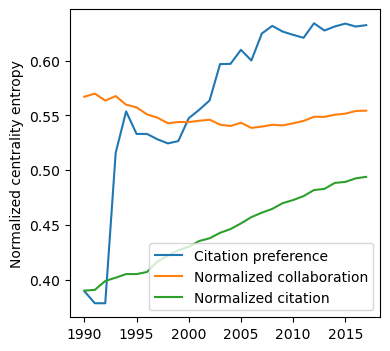

In [13]:
fig, ax = plt.subplots(1,1,figsize=(4,4))

ax.plot(np.arange(syear, eyear+1), yent3, label='Citation preference')
ax.plot(np.arange(syear, eyear+1), yent, label = 'Normalized collaboration')
ax.plot(np.arange(syear, eyear+1), yent2, label = 'Normalized citation')

ax.set_ylabel('Normalized centrality entropy')
plt.legend()
plt.savefig(os.path.join(path2figures, 'FigSI_networkentropy.pdf'))
plt.show()

## Source Data for Supplementary Figs. S11 and S12

The values plotted, written to `Source Data/SourceData_FigS11.xlsx` (the edge lists of panels A and B) and `SourceData_FigS12.xlsx`.

In [14]:
from sourcedatautils import write_source_data

write_source_data('SourceData_FigS11.xlsx', 'Supplementary Figure 11: Traditional bibliometric networks.',
                  ('A) Edges of the normalized collaboration network in 2017 (threshold 0.025). B) Edges of the normalized '
                   'citation network in 2017 (citations within a 5-year window, threshold 0.03). Both networks are '
                   'restricted to the countries of the citation preference network.'),
                  [('S11A', 'Edges of the normalized collaboration network in 2017.', normcoauthornet_df.rename(columns={'source':'Source country', 'target':'Target country'})),
                   ('S11B', 'Edges of the normalized citation network in 2017.', normcitenet_df.rename(columns={'source':'Source country', 'target':'Target country'}))])

s12 = pd.DataFrame({'Year': np.arange(syear, eyear+1), 'Citation preference': yent3,
                    'Normalized collaboration': yent, 'Normalized citation': yent2})
write_source_data('SourceData_FigS12.xlsx', 'Supplementary Figure 12: Normalized entropy of network centrality.',
                  'Normalized entropy of the PageRank centrality of the citation preference, normalized collaboration and normalized citation networks in each year.',
                  [('S12', 'Normalized entropy in each year.', s12)])

wrote /Users/psp2nq/Documents/NationalBiasCode/Source Data/SourceData_FigS11.xlsx
wrote /Users/psp2nq/Documents/NationalBiasCode/Source Data/README.txt
wrote /Users/psp2nq/Documents/NationalBiasCode/Source Data/SourceData_FigS12.xlsx
wrote /Users/psp2nq/Documents/NationalBiasCode/Source Data/README.txt
